In [1]:
%load_ext nb_black
import os
from glob import glob
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
import pickle
from scipy import stats
from os.path import join
import scipy
from pathlib import Path
from collections import defaultdict
from datetime import datetime
import seaborn as sns

<IPython.core.display.Javascript object>

In [2]:
plt.rcParams.update(
    {
        "font.size": 6,  # Default font size for all text
        "axes.titlesize": 6,  # Axes title
        "axes.labelsize": 6,  # Axes labels
        "xtick.labelsize": 6,  # X-axis tick labels
        "ytick.labelsize": 6,  # Y-axis tick labels
        "legend.fontsize": 6,  # Legend text
        "figure.titlesize": 6,  # Figure title
        "lines.linewidth": 0.5,  # Default line width
        "figure.figsize": (9 / 2.54, 6 / 2.54),  # Default figure size in cm
        "figure.dpi": 150,  # Default DPI for figures
        "xtick.major.size": 1,  # X-axis major tick length
        "ytick.major.size": 1,  # Y-axis major tick length
        "figure.constrained_layout.use": True,  # Use constrained layout by default
    }
)

<IPython.core.display.Javascript object>

In [3]:
tol_bright_20 = [
    "#4477AA",  # blue
    "#66CCEE",  # cyan
    "#228833",  # green
    "#CCBB44",  # mustard
    "#EE6677",  # red
    "#AA3377",  # purple
    "#BBBBBB",  # grey
    "#77AADD",  # light blue
    "#EE8866",  # orange
    "#EEDD88",  # pale yellow
    "#FFAABB",  # pink
    "#99DDFF",  # sky blue
    "#44AA99",  # teal
    "#117733",  # dark green
    "#332288",  # indigo
    "#DDCC77",  # sand
    "#CC6677",  # rose
    "#88CCAA",  # mint
    "#999933",  # olive
    "#882255",  # burgundy
]

colors20 = sns.color_palette(tol_bright_20)
colors20

[(0.26666666666666666, 0.4666666666666667, 0.6666666666666666),
 (0.4, 0.8, 0.9333333333333333),
 (0.13333333333333333, 0.5333333333333333, 0.2),
 (0.8, 0.7333333333333333, 0.26666666666666666),
 (0.9333333333333333, 0.4, 0.4666666666666667),
 (0.6666666666666666, 0.2, 0.4666666666666667),
 (0.7333333333333333, 0.7333333333333333, 0.7333333333333333),
 (0.4666666666666667, 0.6666666666666666, 0.8666666666666667),
 (0.9333333333333333, 0.5333333333333333, 0.4),
 (0.9333333333333333, 0.8666666666666667, 0.5333333333333333),
 (1.0, 0.6666666666666666, 0.7333333333333333),
 (0.6, 0.8666666666666667, 1.0),
 (0.26666666666666666, 0.6666666666666666, 0.6),
 (0.06666666666666667, 0.4666666666666667, 0.2),
 (0.2, 0.13333333333333333, 0.5333333333333333),
 (0.8666666666666667, 0.8, 0.4666666666666667),
 (0.8, 0.4, 0.4666666666666667),
 (0.5333333333333333, 0.8, 0.6666666666666666),
 (0.6, 0.6, 0.2),
 (0.5333333333333333, 0.13333333333333333, 0.3333333333333333)]

<IPython.core.display.Javascript object>

In [4]:
def get_meta_from_file_path(file_path):
    meta = file_path.split("/")
    version = meta[-2]
    name = meta[-1].split("_")
    var = name[0]
    mdl = name[2]
    exp = name[3]
    label = name[4]
    time = name[-1].split(".")[0].split("-")
    time0 = time[0]
    time1 = time[1]

    return var, mdl, exp, label, version, time0, time1

<IPython.core.display.Javascript object>

In [5]:
cmip6_data_dir = Path.cwd().parent
res_dir = Path.cwd().parent / "processed"

<IPython.core.display.Javascript object>

In [6]:
file_paths = [f for f in res_dir.rglob("*.nc") if "global_annual_data" in str(f)]
file_paths

[PosixPath('/Users/gatang/Research/Data/CMIP6/processed/global_annual_data/CMIP6_ESM_carbon_nitrogen_cycle_outputs_global_annual_processed_by_Gang_Tang.nc')]

<IPython.core.display.Javascript object>

In [7]:
ds_global_annual = xr.open_dataset(file_paths[0])

<IPython.core.display.Javascript object>

In [8]:
mdl_list = ds_global_annual.model.data
exp_list = ds_global_annual.experiment.data

<IPython.core.display.Javascript object>

In [9]:
def _plot_vars_by_exp(ds, exp_list, var_list, delta=False, mean_std=False):
    col = len(exp_list)
    row = len(var_list)

    fig, axs = plt.subplots(
        row,
        col,
        figsize=(3.5 * col / 2.54, 3.5 * row / 2.54),
    )

    for i, var in enumerate(var_list):
        y_min = np.inf
        y_max = -np.inf

        for j, exp in enumerate(exp_list):
            ax = axs[i, j]
            da = ds[var].sel(experiment=exp)
            units = da.attrs["units"]

            if delta:
                baseline_year = 2015 if "ssp" in exp else 1850
                da = da - da.sel(time=baseline_year)

            for mdl, color in zip(mdl_list, colors20):
                values = da.sel(model=mdl)
                if ds["nVeg"].sel(model=mdl).sum() == 0:
                    linestyle = "--"
                else:
                    linestyle = "-"

                ax.plot(
                    da.time,
                    values,
                    label=mdl,
                    linewidth=0.5,
                    color=color,
                    linestyle=linestyle,
                )

                y_min = min(y_min, values.min().data)
                y_max = max(y_max, values.max().data)
                y_range = y_max - y_min

            if mean_std:
                mean = da.mean(dim="model")
                std = da.std(dim="model")

                ax.plot(
                    da.time,
                    mean,
                    color="black",
                    linewidth=1.5,
                    label="multi-model mean",
                )
                ax.fill_between(
                    da.time,
                    mean - std,
                    mean + std,
                    color="black",
                    alpha=0.15,
                    label="±1 SD",
                    linewidth=0,
                )

            if i == 0:
                ax.set_title(exp)

        for ax in axs[i, :]:
            ax.set_ylim(y_min - y_range * 0.05, y_max + y_range * 0.05)
        for ax in axs[i, 1:]:
            ax.tick_params(axis="y", labelleft=False)

        prefix = "Δ" if delta else ""
        axs[i, 0].set_ylabel(prefix + var + f" ({units})")

    # Single figure-level legend at the bottom
    handles, labels = axs[0, 0].get_legend_handles_labels()
    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, -0.05),
        ncol=5,
        frameon=False,
    )

<IPython.core.display.Javascript object>

In [10]:
state_vars = [
    "cVeg",
    "cLitter",
    "cSoil",
    "cProduct",
    "cLand",
    "nVeg",
    "nLitter",
    "nSoil",
    "nMineral",
    "nLand",
]

flux_vars = ["npp", "gpp", "ra", "rh", "nbp", "fBNF", "fNnetmin", "fNup", "fNloss"]

<IPython.core.display.Javascript object>

In [11]:
plot_exps = [
    "historical",
    "ssp126",
    "ssp245",
    "ssp370",
    "ssp585",
]

<IPython.core.display.Javascript object>

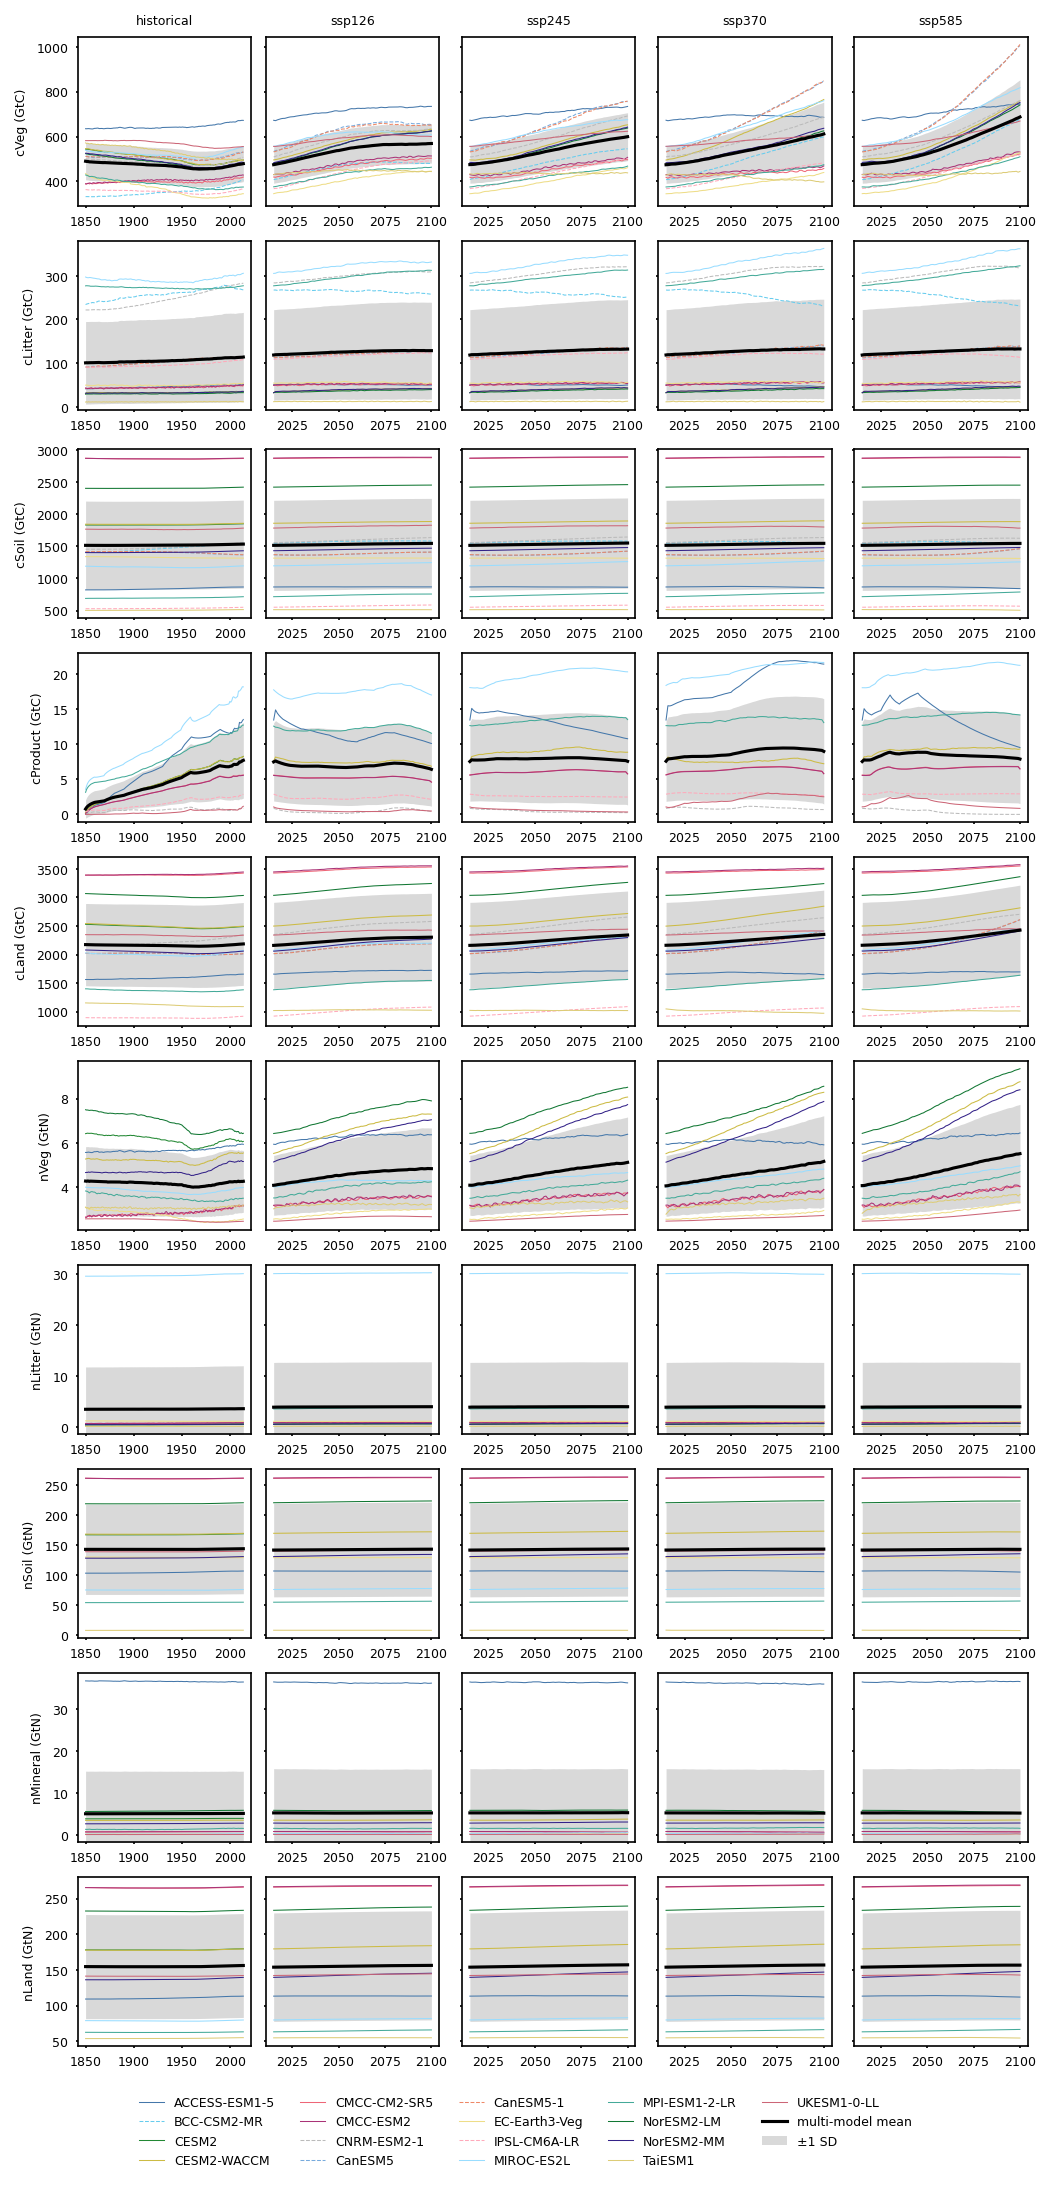

<IPython.core.display.Javascript object>

In [12]:
_plot_vars_by_exp(ds_global_annual, plot_exps, state_vars, mean_std=True)

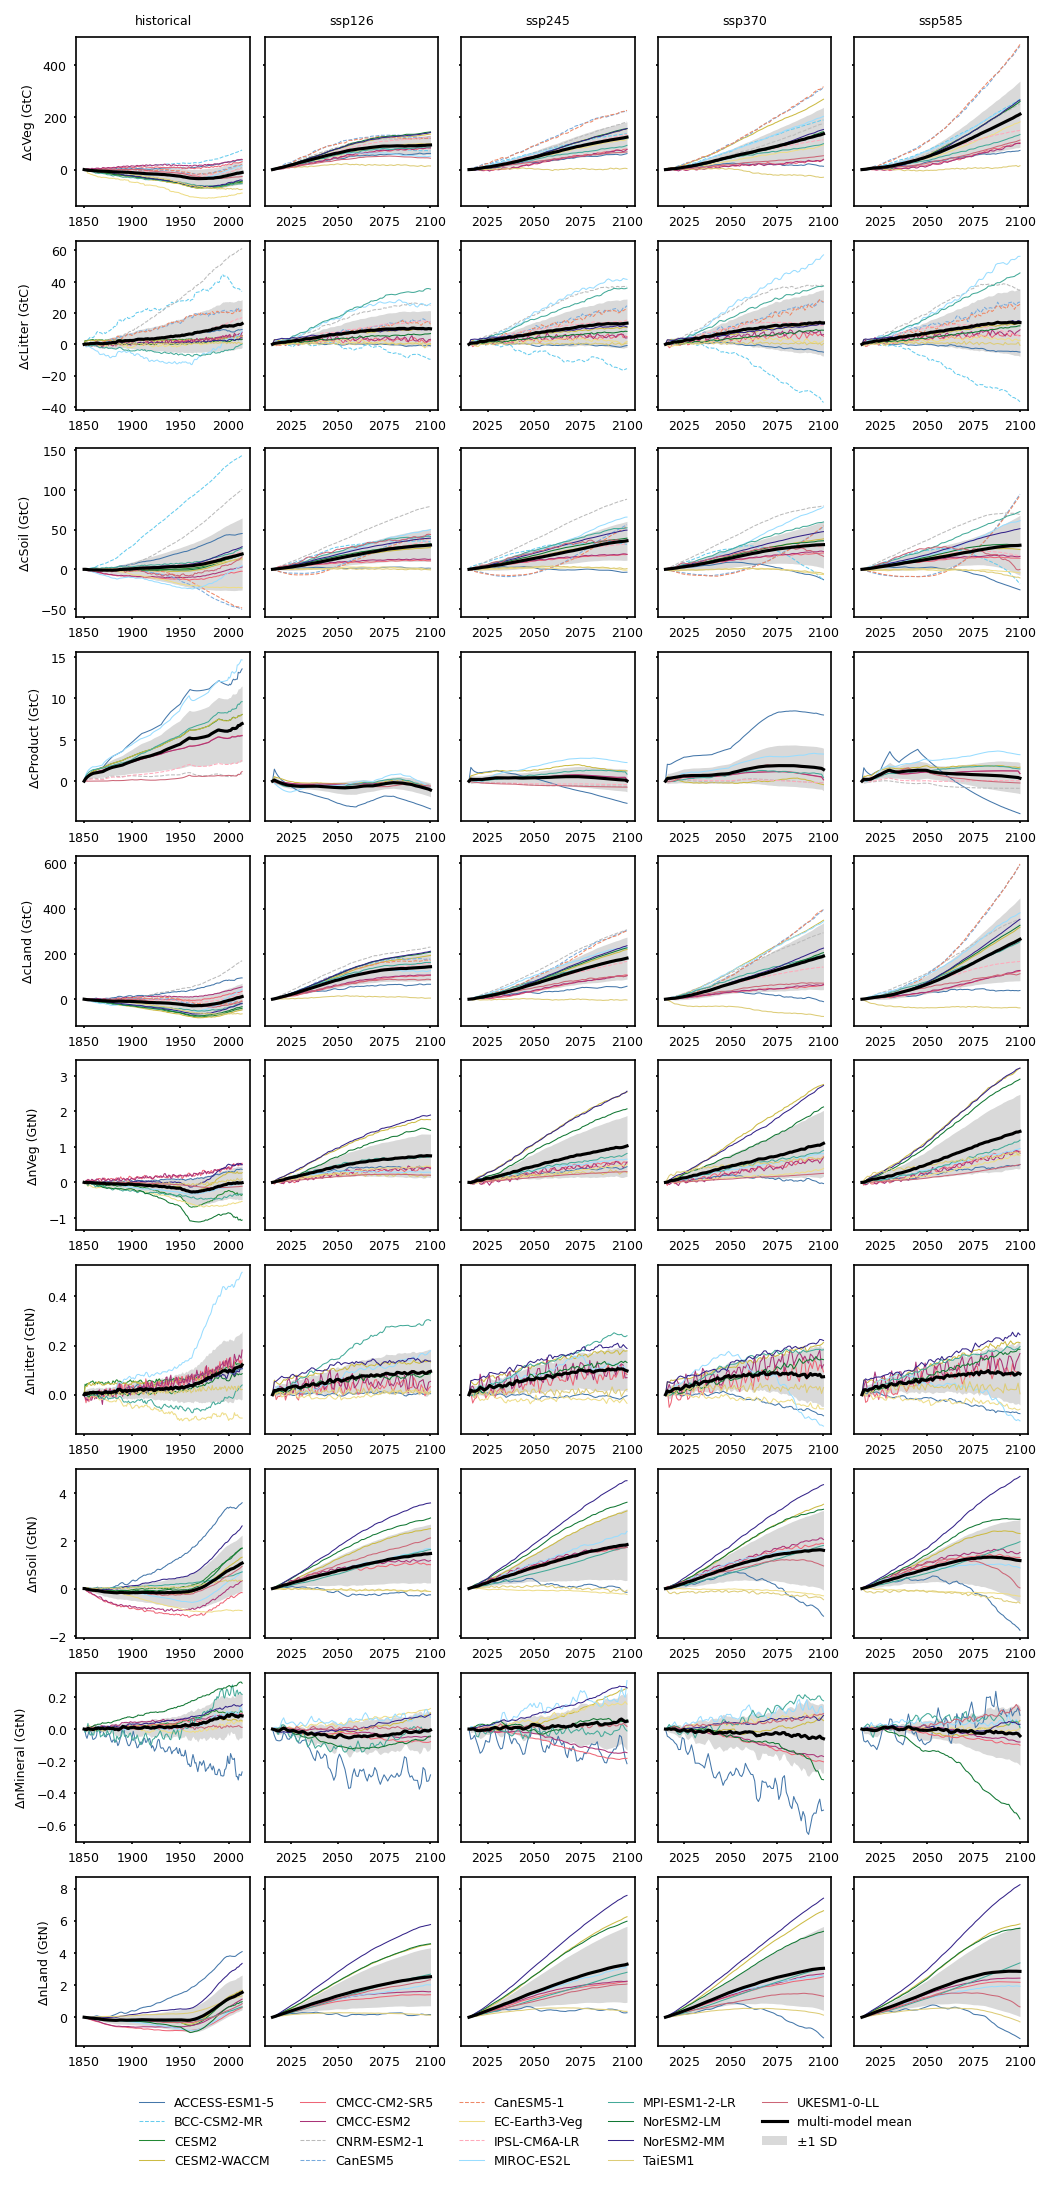

<IPython.core.display.Javascript object>

In [13]:
_plot_vars_by_exp(ds_global_annual, plot_exps, state_vars, delta=True, mean_std=True)

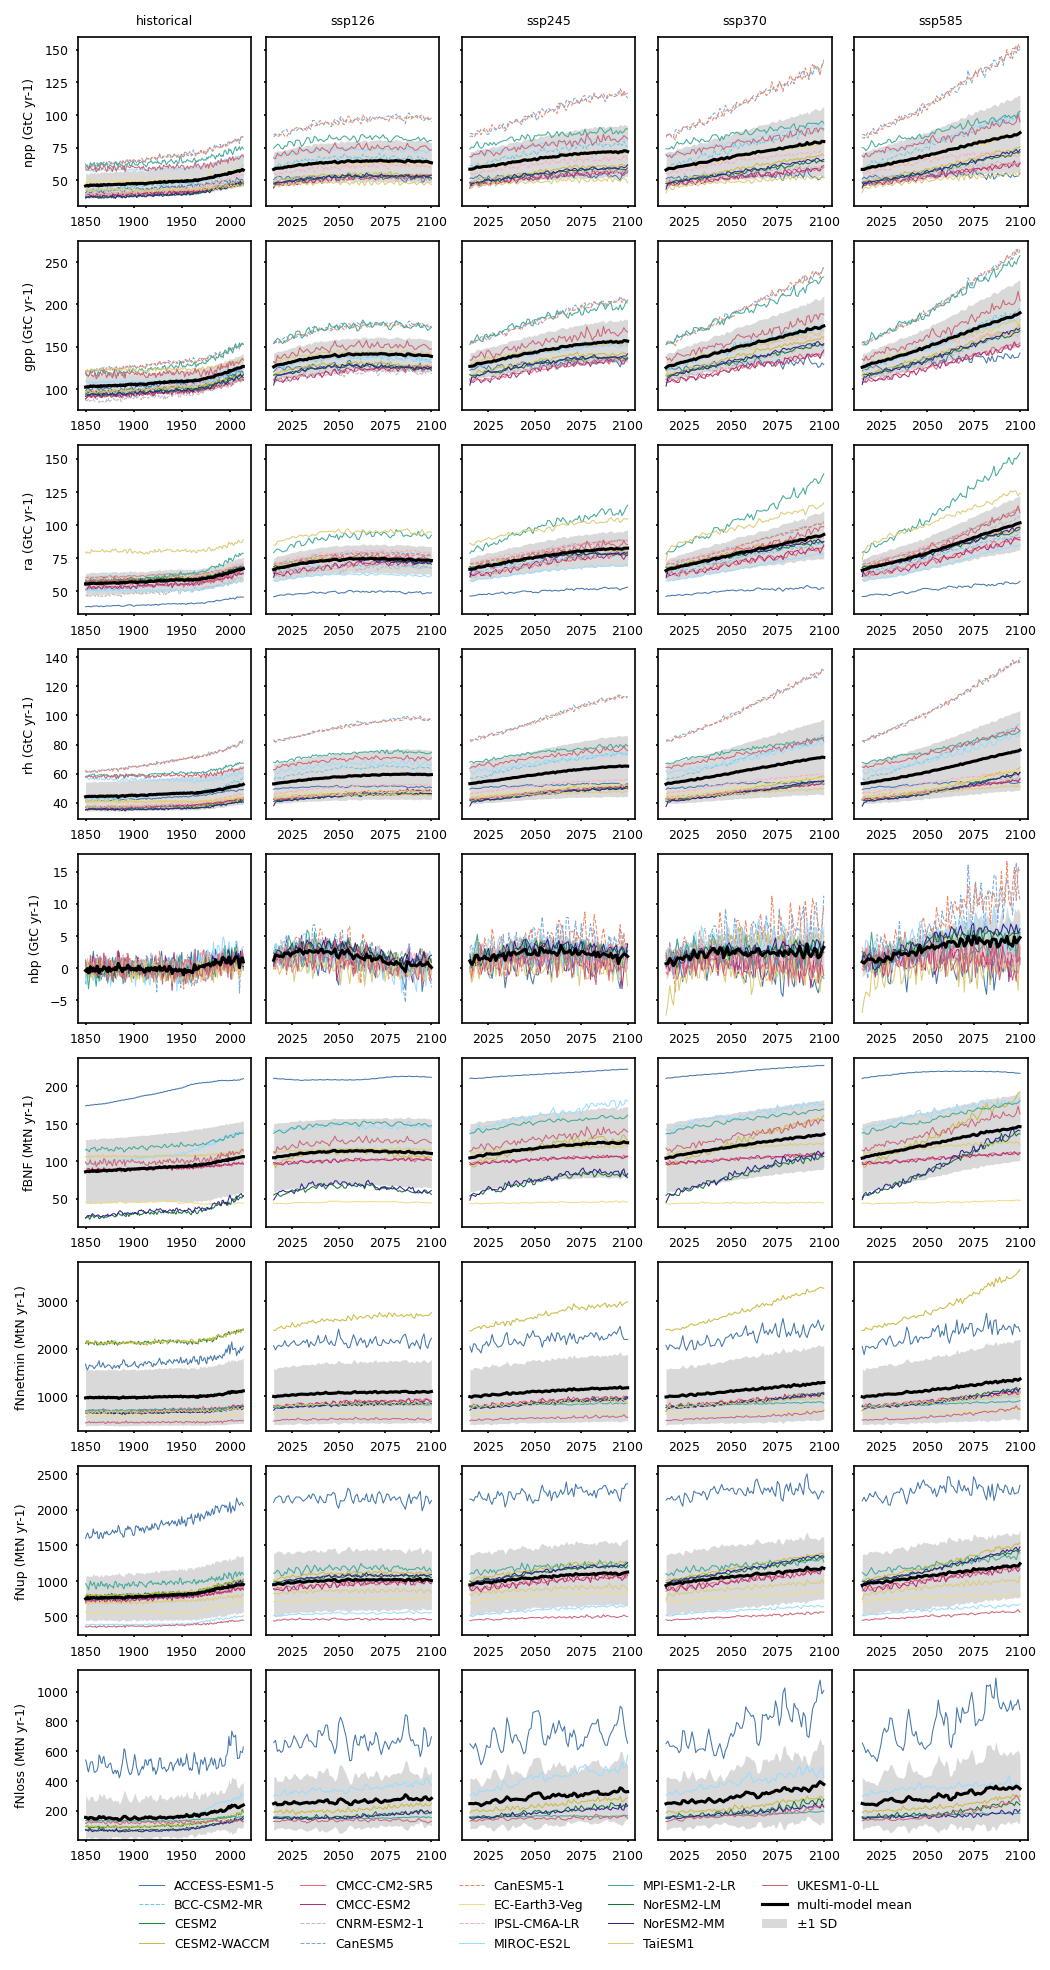

<IPython.core.display.Javascript object>

In [14]:
_plot_vars_by_exp(ds_global_annual, plot_exps, flux_vars, mean_std=True)